# Phishing Website Detection using Machine Learning

## Phase 2: Model Training

In [1]:
# ============================================================
#  Phishing URL Dataset — Data Preprocessing Pipeline
#  Picks up exactly where the Kaggle notebook left off
# ============================================================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, chi2
import warnings
warnings.filterwarnings('ignore')

# ── 1. LOAD DATA ─────────────────────────────────────────────
# Update this path to wherever your dataset.csv is stored
df = pd.read_csv('dataset.csv')

print("=" * 55)
print("STEP 1 — Raw Data Loaded")
print("=" * 55)
print(f"  Shape        : {df.shape}")
print(f"  Columns      : {df.shape[1]}")
print(f"  Missing vals : {df.isnull().sum().sum()}")


# ── 2. DROP UNNECESSARY COLUMNS ──────────────────────────────
# 'index' is just a row ID — no predictive value
df = df.drop(columns=['index'])

print("\n" + "=" * 55)
print("STEP 2 — Dropped 'index' column")
print(f"  New shape    : {df.shape}")


# ── 3. FIX LABEL ENCODING ────────────────────────────────────
# Original labels: 1 = Legitimate, -1 = Phishing
# We remap -1 → 0 so it becomes a clean binary problem:
#   0 = Phishing   |   1 = Legitimate

df['Result'] = df['Result'].replace(-1, 0)

print("\n" + "=" * 55)
print("STEP 3 — Remapped Target Labels  (-1 → 0)")
print(f"  Class distribution:\n{df['Result'].value_counts().to_string()}")
print(f"  Phishing  : {(df['Result']==0).sum()} ({(df['Result']==0).mean()*100:.1f}%)")
print(f"  Legitimate: {(df['Result']==1).sum()} ({(df['Result']==1).mean()*100:.1f}%)")


# ── 4. REMAP FEATURE VALUES (0 stays, -1 → 0 for features) ──
# Features use:  1=legitimate, 0=suspicious, -1=phishing
# Keeping -1 can confuse tree models (ordinal assumption).
# We remap feature -1 → 0, making all features binary/ternary
# with values in {0, 1} or {0, 0.5, 1}.

# Strategy: map {-1: 0, 0: 0.5, 1: 1} for ternary features
#           map {-1: 0, 1: 1}          for binary features

feature_cols = [c for c in df.columns if c != 'Result']

binary_features  = []   # only 2 unique values
ternary_features = []   # 3 unique values (includes 0)

for col in feature_cols:
    unique = set(df[col].unique())
    if unique == {-1, 1}:
        binary_features.append(col)
    else:
        ternary_features.append(col)

# Remap binary features: -1 → 0
for col in binary_features:
    df[col] = df[col].replace(-1, 0)

# Remap ternary features: -1 → 0, 0 → 0.5, 1 → 1
for col in ternary_features:
    df[col] = df[col].replace({-1: 0, 0: 0.5, 1: 1})

print("\n" + "=" * 55)
print("STEP 4 — Feature Value Remapping")
print(f"  Binary features  ({len(binary_features)}) : -1 → 0, 1 → 1")
print(f"  Ternary features ({len(ternary_features)}) : -1 → 0, 0 → 0.5, 1 → 1")
print(f"  Sample binary   : {binary_features[:4]}")
print(f"  Sample ternary  : {ternary_features[:4]}")


# ── 5. DROP HIGHLY CORRELATED FEATURES ───────────────────────
# The notebook noted popUpWindow & Favicon are highly correlated.
# We compute full correlation matrix and drop one of each pair
# with correlation > 0.90.

corr_matrix = df[feature_cols].corr().abs()
upper_tri = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = [
    (col, row, upper_tri.loc[row, col])
    for col in upper_tri.columns
    for row in upper_tri.index
    if pd.notna(upper_tri.loc[row, col]) and upper_tri.loc[row, col] > 0.90
]

cols_to_drop_corr = list(set([pair[1] for pair in high_corr_pairs]))
df = df.drop(columns=cols_to_drop_corr)
feature_cols = [c for c in df.columns if c != 'Result']

print("\n" + "=" * 55)
print("STEP 5 — Removed Highly Correlated Features (threshold > 0.90)")
if high_corr_pairs:
    for a, b, v in high_corr_pairs:
        print(f"  Dropped '{b}' (corr with '{a}' = {v:.2f})")
else:
    print("  No feature pairs exceeded the 0.90 threshold.")
print(f"  Remaining features: {len(feature_cols)}")


# ── 6. FEATURE SELECTION (Chi-2) ─────────────────────────────
# Select top K features using chi-squared test.
# Since all values are now in [0, 1], chi2 is valid here.

X = df[feature_cols]
y = df['Result']

K = min(20, len(feature_cols))   # keep top 20 or all if fewer
selector = SelectKBest(chi2, k=K)
selector.fit(X, y)

selected_mask   = selector.get_support()
selected_feats  = X.columns[selected_mask].tolist()
dropped_feats   = X.columns[~selected_mask].tolist()

X_selected = pd.DataFrame(selector.transform(X), columns=selected_feats)

print("\n" + "=" * 55)
print(f"STEP 6 — Chi-2 Feature Selection (top {K})")
print(f"  Selected : {selected_feats}")
if dropped_feats:
    print(f"  Dropped  : {dropped_feats}")


# ── 7. TRAIN / TEST SPLIT ────────────────────────────────────
# 80% train, 20% test — stratified to preserve class balance

X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\n" + "=" * 55)
print("STEP 7 — Train / Test Split  (80 / 20, stratified)")
print(f"  X_train : {X_train.shape}   y_train : {y_train.shape}")
print(f"  X_test  : {X_test.shape}    y_test  : {y_test.shape}")
print(f"  Train class balance : {y_train.value_counts().to_dict()}")
print(f"  Test  class balance : {y_test.value_counts().to_dict()}")


# ── 8. SCALING (optional for tree models, useful for others) ──
# XGBoost doesn't need scaling, but Logistic Regression / SVM do.
# We prepare both scaled and unscaled versions.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on train only
X_test_scaled  = scaler.transform(X_test)         # transform test

X_train_scaled = pd.DataFrame(X_train_scaled, columns=selected_feats)
X_test_scaled  = pd.DataFrame(X_test_scaled,  columns=selected_feats)

print("\n" + "=" * 55)
print("STEP 8 — Standard Scaling Applied")
print("  (Fit on train only — no data leakage)")
print(f"  X_train_scaled mean (first 3): "
      f"{X_train_scaled.iloc[:, :3].mean().round(4).values}")
print(f"  X_train_scaled std  (first 3): "
      f"{X_train_scaled.iloc[:, :3].std().round(4).values}")


# ── 9. SUMMARY ───────────────────────────────────────────────
print("\n" + "=" * 55)
print("✅  PREPROCESSING COMPLETE — Data Ready for Modelling")
print("=" * 55)
print(f"""
  Outputs available:
  ┌─────────────────────────────────────────────┐
  │  For tree models (XGBoost, RandomForest):   │
  │    X_train, X_test, y_train, y_test         │
  │                                             │
  │  For linear models (LogReg, SVM, KNN):      │
  │    X_train_scaled, X_test_scaled            │
  │    y_train, y_test                          │
  │                                             │
  │  Feature count : {len(selected_feats):<3}                          │
  │  Train samples : {len(X_train):<5}                        │
  │  Test  samples : {len(X_test):<5}                        │
  └─────────────────────────────────────────────┘
""")


STEP 1 — Raw Data Loaded
  Shape        : (11055, 32)
  Columns      : 32
  Missing vals : 0

STEP 2 — Dropped 'index' column
  New shape    : (11055, 31)

STEP 3 — Remapped Target Labels  (-1 → 0)
  Class distribution:
Result
1    6157
0    4898
  Phishing  : 4898 (44.3%)
  Legitimate: 6157 (55.7%)

STEP 4 — Feature Value Remapping
  Binary features  (21) : -1 → 0, 1 → 1
  Ternary features (9) : -1 → 0, 0 → 0.5, 1 → 1
  Sample binary   : ['having_IPhaving_IP_Address', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting']
  Sample ternary  : ['URLURL_Length', 'having_Sub_Domain', 'SSLfinal_State', 'URL_of_Anchor']

STEP 5 — Removed Highly Correlated Features (threshold > 0.90)
  Dropped 'Favicon' (corr with 'popUpWidnow' = 0.94)
  Remaining features: 29

STEP 6 — Chi-2 Feature Selection (top 20)
  Selected : ['having_IPhaving_IP_Address', 'URLURL_Length', 'Shortining_Service', 'having_At_Symbol', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registerat

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

In [3]:
import sys
import os

sys.path.append(os.getcwd())
print(sys.path)

['C:\\Users\\achyu\\AppData\\Local\\Python\\pythoncore-3.15-64\\python315.zip', 'C:\\Users\\achyu\\AppData\\Local\\Python\\pythoncore-3.15-64\\DLLs', 'C:\\Users\\achyu\\AppData\\Local\\Python\\pythoncore-3.15-64\\Lib', 'C:\\Users\\achyu\\AppData\\Local\\Python\\pythoncore-3.15-64', 'c:\\Users\\achyu\\OneDrive\\Desktop\\RM project\\.venv', '', 'c:\\Users\\achyu\\OneDrive\\Desktop\\RM project\\.venv\\Lib\\site-packages', 'c:\\Users\\achyu\\OneDrive\\Desktop\\RM project']


In [4]:
lr = LogisticRegression()
lr.fit(X_train_scaled, y_train)

rf = RandomForestClassifier()
rf.fit(X_train, y_train)

svm = SVC(probability=True)
svm.fit(X_train_scaled, y_train)

dt = DecisionTreeClassifier()
dt.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [5]:
from sklearn.metrics import accuracy_score, classification_report

models = {
    "Logistic Regression": lr,
    "Random Forest": rf,
    "SVM": svm,
    "Decision Tree": dt
}

results = {}

for name, model in models.items():
    
    # -----------------------------
    # TRAINING ACCURACY
    # -----------------------------
    if name in ["Logistic Regression", "SVM"]:
        train_acc = model.score(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        train_acc = model.score(X_train, y_train)
        y_pred = model.predict(X_test)

    # -----------------------------
    # TEST ACCURACY
    # -----------------------------
    test_acc = accuracy_score(y_test, y_pred)

    results[name] = test_acc

    print(f"\n{name}")
    print("Training Accuracy:", train_acc)
    print("Testing Accuracy:", test_acc)


Logistic Regression
Training Accuracy: 0.9254862053369516
Testing Accuracy: 0.9289914066033469

Random Forest
Training Accuracy: 0.9853007688828584
Testing Accuracy: 0.9696969696969697

SVM
Training Accuracy: 0.954093170511081
Testing Accuracy: 0.9497964721845319

Decision Tree
Training Accuracy: 0.9853007688828584
Testing Accuracy: 0.9606512890094979


In [6]:
import pandas as pd

results_df = pd.DataFrame(list(results.items()), columns=["Model", "Accuracy"])
results_df

,Model,Accuracy
0,Logistic Regression,0.928991
1,Random Forest,0.969697
2,SVM,0.949796
3,Decision Tree,0.960651


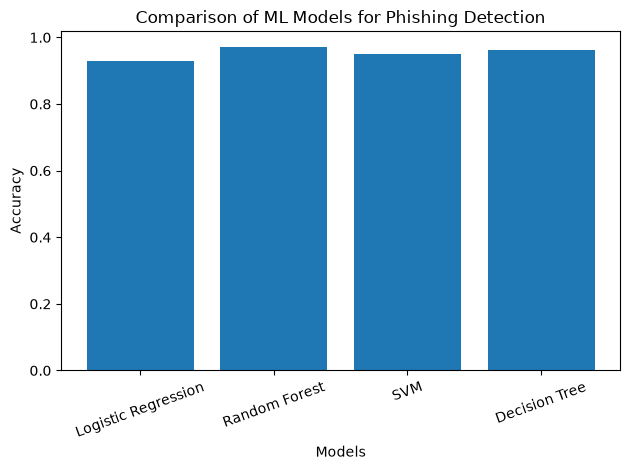

In [7]:
import matplotlib.pyplot as plt

plt.figure()

plt.bar(results_df["Model"], results_df["Accuracy"])

plt.title("Comparison of ML Models for Phishing Detection")
plt.xlabel("Models")
plt.ylabel("Accuracy")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [8]:
import pandas as pd

feature_importance = rf.feature_importances_
features = X_train.columns

importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": feature_importance
}).sort_values(by="Importance", ascending=False)

importance_df.head(10)

,Feature,Importance
6,SSLfinal_State,0.350979
10,URL_of_Anchor,0.238594
16,web_traffic,0.080176
5,having_Sub_Domain,0.068667
11,Links_in_tags,0.044407
4,Prefix_Suffix,0.043549
9,Request_URL,0.021038
12,SFH,0.020187
14,age_of_domain,0.018196
7,Domain_registeration_length,0.016140


In [9]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid = GridSearchCV(RandomForestClassifier(), param_grid, cv=3, n_jobs=-1)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
print("Best Parameters:", grid.best_params_)

Best Parameters: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 100}


In [10]:
y_pred = best_model.predict(X_test)
from sklearn.metrics import accuracy_score

print("Tuned Accuracy:", accuracy_score(y_test, y_pred))

Tuned Accuracy: 0.9724106739032112


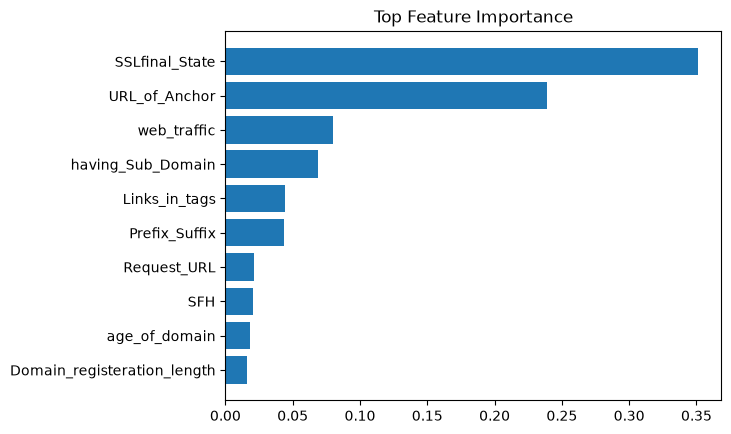

In [11]:
import matplotlib.pyplot as plt

plt.barh(importance_df["Feature"][:10], importance_df["Importance"][:10])
plt.gca().invert_yaxis()
plt.title("Top Feature Importance")
plt.show()

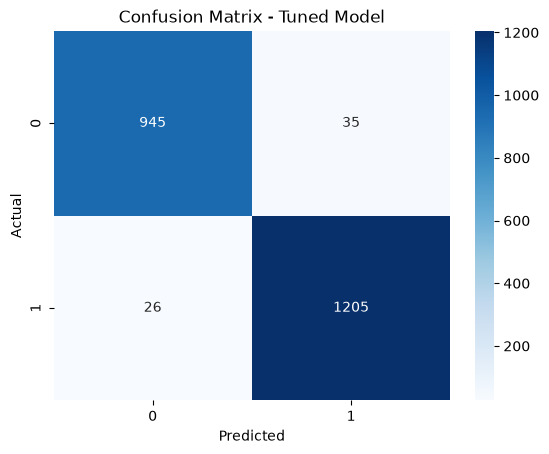

In [12]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix - Tuned Model")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

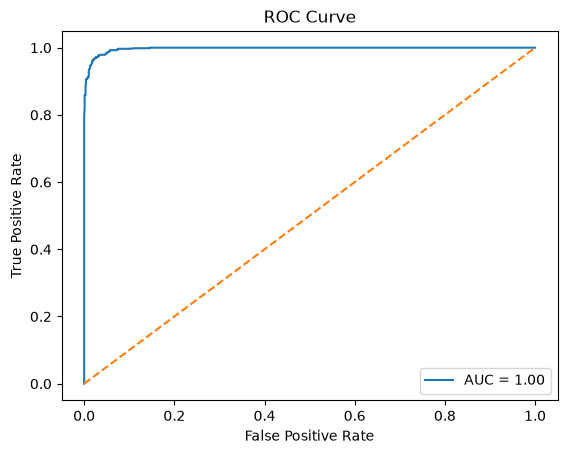

In [13]:
from sklearn.metrics import roc_curve, auc

y_prob = best_model.predict_proba(X_test)[:,1]

fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

import matplotlib.pyplot as plt

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0,1], [0,1], linestyle='--')
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

In [14]:
from sklearn.ensemble import VotingClassifier

ensemble = VotingClassifier(
    estimators=[
        ('rf', rf),
        ('svm', svm)
    ],
    voting='soft'
)

ensemble.fit(X_train, y_train)
y_pred_ens = ensemble.predict(X_test)

from sklearn.metrics import accuracy_score
print("Ensemble Accuracy:", accuracy_score(y_test, y_pred_ens))

Ensemble Accuracy: 0.9692446856625961


In [15]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(best_model, X_train, y_train, cv=5)

print("Cross-validation accuracy:", scores.mean())
print("Std Dev:", scores.std())

Cross-validation accuracy: 0.9603122146366918
Std Dev: 0.004034071720760284


In [16]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# For tuned model (best_model)
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:,1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

metrics

{'Accuracy': 0.9724106739032112,
 'Precision': 0.9717741935483871,
 'Recall': 0.9788789601949635,
 'F1 Score': 0.9753136382031566,
 'ROC-AUC': 0.9972235116629916}

In [17]:
baseline_pred = rf.predict(X_test)

baseline = {
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred),
    "Recall": recall_score(y_test, baseline_pred),
    "F1 Score": f1_score(y_test, baseline_pred),
    "ROC-AUC": roc_auc_score(y_test, rf.predict_proba(X_test)[:,1])
}

import pandas as pd

comparison_df = pd.DataFrame({
    "Metric": baseline.keys(),
    "Baseline": baseline.values(),
    "Tuned": metrics.values()
})

comparison_df["Improvement"] = comparison_df["Tuned"] - comparison_df["Baseline"]

comparison_df

,Metric,Baseline,Tuned,Improvement
0,Accuracy,0.969697,0.972411,0.002714
1,Precision,0.971637,0.971774,0.000137
2,Recall,0.974005,0.978879,0.004874
3,F1 Score,0.972819,0.975314,0.002494
4,ROC-AUC,0.996863,0.997224,0.000361


In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# -------------------------------
# BASELINE MODEL (Random Forest)
# -------------------------------
baseline_pred = rf.predict(X_test)
baseline_prob = rf.predict_proba(X_test)[:,1]

baseline = {
    "Accuracy": accuracy_score(y_test, baseline_pred),
    "Precision": precision_score(y_test, baseline_pred),
    "Recall": recall_score(y_test, baseline_pred),
    "F1 Score": f1_score(y_test, baseline_pred),
    "ROC-AUC": roc_auc_score(y_test, baseline_prob)
}

# -------------------------------
# TUNED MODEL
# -------------------------------
tuned_pred = best_model.predict(X_test)
tuned_prob = best_model.predict_proba(X_test)[:,1]

tuned = {
    "Accuracy": accuracy_score(y_test, tuned_pred),
    "Precision": precision_score(y_test, tuned_pred),
    "Recall": recall_score(y_test, tuned_pred),
    "F1 Score": f1_score(y_test, tuned_pred),
    "ROC-AUC": roc_auc_score(y_test, tuned_prob)
}

# -------------------------------
# CREATE COMPARISON TABLE
# -------------------------------
comparison_df = pd.DataFrame({
    "Metric": baseline.keys(),
    "Baseline": baseline.values(),
    "Tuned": tuned.values()
})

# -------------------------------
# CALCULATE DELTA (IMPROVEMENT)
# -------------------------------
comparison_df["Delta"] = comparison_df["Tuned"] - comparison_df["Baseline"]
comparison_df = comparison_df.round(4)

# -------------------------------
# DISPLAY RESULT
# -------------------------------
comparison_df

,Metric,Baseline,Tuned,Delta
0,Accuracy,0.9697,0.9724,0.0027
1,Precision,0.9716,0.9718,0.0001
2,Recall,0.9740,0.9789,0.0049
3,F1 Score,0.9728,0.9753,0.0025
4,ROC-AUC,0.9969,0.9972,0.0004


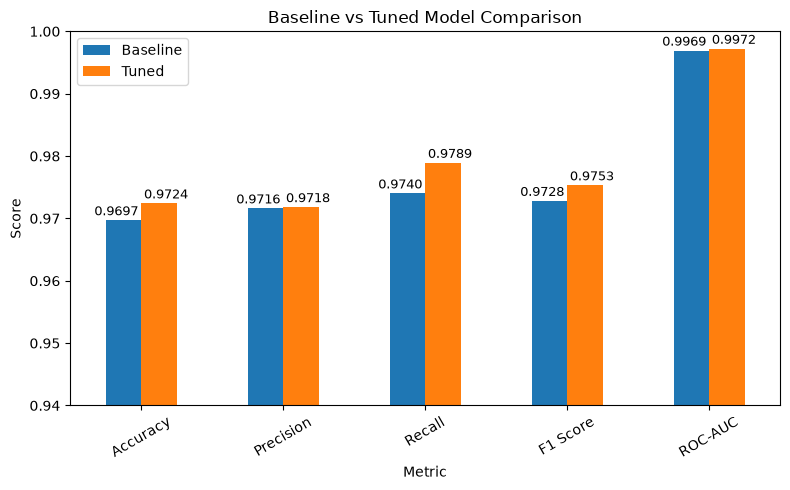

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# Plot
ax = comparison_df.set_index("Metric")[["Baseline", "Tuned"]].plot(
    kind="bar",
    figsize=(8,5)
)

# Zoom
plt.ylim(0.94, 1.0)

# 🔥 FIX OVERLAPPING LABELS
for i, container in enumerate(ax.containers):
    for bar in container:
        height = bar.get_height()

        # shift labels slightly left/right
        offset = -0.05 if i == 0 else 0.05

        ax.text(
            bar.get_x() + bar.get_width()/2 + offset,
            height + 0.0008,
            f"{height:.4f}",
            ha='center',
            fontsize=9
        )

# Formatting
plt.title("Baseline vs Tuned Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()

plt.show()

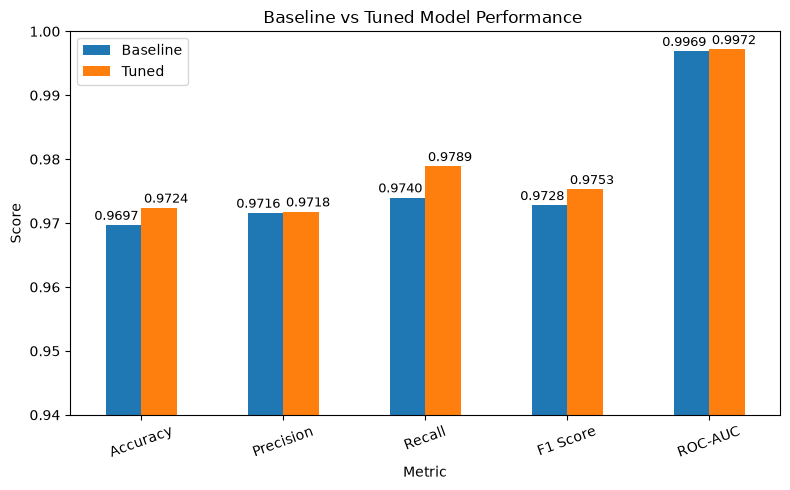

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Plot
ax = comparison_df.set_index("Metric")[["Baseline", "Tuned"]].plot(
    kind="bar",
    figsize=(8,5)
)

# Zoom
plt.ylim(0.94, 1.0)

# 🔥 FIX OVERLAPPING LABELS
for i, container in enumerate(ax.containers):
    for bar in container:
        height = bar.get_height()

        # shift left for baseline, right for tuned
        offset = -0.05 if i == 0 else 0.05

        ax.text(
            bar.get_x() + bar.get_width()/2 + offset,
            height + 0.0008,
            f"{height:.4f}",
            ha='center',
            fontsize=9
        )

# Labels & formatting
plt.title("Baseline vs Tuned Model Performance ")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()

plt.show()

In [21]:
misclassified = X_test[y_test != y_pred]

print("Misclassified samples:", len(misclassified))

Misclassified samples: 61


In [22]:
print(y_test.value_counts())

Result
1    1231
0     980
Name: count, dtype: int64


In [23]:
import pickle

pickle.dump(best_model, open("model.pkl", "wb"))

In [24]:
!pip install scikit-learn pandas matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [25]:
!pip install seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
pip install flask

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [27]:
pip install tldextract requests beautifulsoup4


  Using cached beautifulsoup4-4.15.0-py3-none-any.whl.metadata (3.8 kB)
  Using cached soupsieve-3.0.4-py3-none-any.whl.metadata (4.4 kB)
Using cached beautifulsoup4-4.15.0-py3-none-any.whl (109 kB)
Using cached soupsieve-3.0.4-py3-none-any.whl (42 kB)

   -------------------- ------------------- 1/2 [beautifulsoup4]
   -------------------- ------------------- 1/2 [beautifulsoup4]
   ---------------------------------------- 2/2 [beautifulsoup4]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
